# Proyecto Machine Learning: Predicción de Éxito Musical en Spotify

-Emmanuel Chavero

-Benjamin Figueroa

-Daniel Vidal
## Fase 1: Comprensión del Negocio

**Contexto:**
La industria musical es altamente competitiva. Plataformas como Spotify utilizan complejos algoritmos para recomendar música. Entender qué hace que una canción sea popular puede ser la diferencia entre un éxito mundial y un fracaso comercial.

**Objetivo Comercial:**
Analizar las características acústicas (bailabilidad, energía, tempo, etc.) y metadatos de un amplio catálogo de canciones para identificar los factores que impulsan la popularidad de una pista. Esto servirá para ayudar a productores musicales, artistas y sellos discográficos a tomar decisiones informadas sobre composición musical y estrategias de marketing.

**Objetivos de Machine Learning:**
*   Explorar y perfilar un conjunto de datos de 114,000 canciones de Spotify.
*   Preparar los datos para el modelado (limpieza y transformación).
*   **Meta Principal:** Desarrollar un modelo predictivo capaz de estimar el nivel de popularidad (`popularity`) de una canción basándose en sus características de audio (`danceability`, `energy`, `acousticness`, etc.).

**Criterios de Éxito:**
Obtener un modelo de Machine Learning (Regresión o Clasificación si agrupamos la popularidad por rangos) que logre predecir la popularidad con un margen de error aceptable para el negocio, permitiendo identificar potenciales "hits" antes de su lanzamiento.

## Fase 2: Comprensión de los Datos

En esta fase importaremos las librerías necesarias, cargaremos el conjunto de datos y realizaremos un Análisis Exploratorio de Datos (EDA) inicial para conocer la forma, el tipo de variables, la presencia de valores nulos y la distribución estadística de nuestro *dataset*.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Spotify_Tracks_Dataset.csv")

df.head()

In [18]:
print("--- DIMENSIONES DEL DATASET ---")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}\n")

print("--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---")
df.info()

print("\n--- VALORES NULOS ---")
print(df.isnull().sum())

--- DIMENSIONES DEL DATASET ---
Filas: 114000
Columnas: 21

--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticnes

**Conclusiones de la Inspección Inicial:**
1.  **Estructura:** El dataset consta de 114,000 registros y 21 columnas.
2.  **Datos Innecesarios:** Se observa una columna `Unnamed: 0` que actúa como un índice redundante y no aporta valor analítico.
3.  **Calidad de Datos:** El dataset está notablemente limpio. Solo se detecta 1 valor nulo en las columnas de texto (`artists`, `album_name`, `track_name`).
4.  **Tipos de Datos:** Tenemos una mezcla útil de variables categóricas (género, nombre del artista) y variables numéricas continuas/discretas (características de audio como volumen, tempo, energía).

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
count,114000.000000,114000,113999,113999,113999,114000.000000,1.140000e+05,114000,114000.000000,114000.000000,...,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000
unique,NaN,89741,31437,46589,73608,NaN,NaN,2,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,114
top,NaN,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,NaN,NaN,False,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,acoustic
freq,NaN,9,279,195,151,NaN,NaN,104253,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000
mean,56999.500000,NaN,NaN,NaN,NaN,33.238535,2.280292e+05,NaN,0.566800,0.641383,...,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035,NaN
std,32909.109681,NaN,NaN,NaN,NaN,22.305078,1.072977e+05,NaN,0.173542,0.251529,...,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621,NaN
min,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000e+00,NaN,0.000000,0.000000,...,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,28499.750000,NaN,NaN,NaN,NaN,17.000000,1.740660e+05,NaN,0.456000,0.472000,...,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000,NaN
50%,56999.500000,NaN,NaN,NaN,NaN,35.000000,2.129060e+05,NaN,0.580000,0.685000,...,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000,NaN
75%,85499.250000,NaN,NaN,NaN,NaN,50.000000,2.615060e+05,NaN,0.695000,0.854000,...,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000,NaN


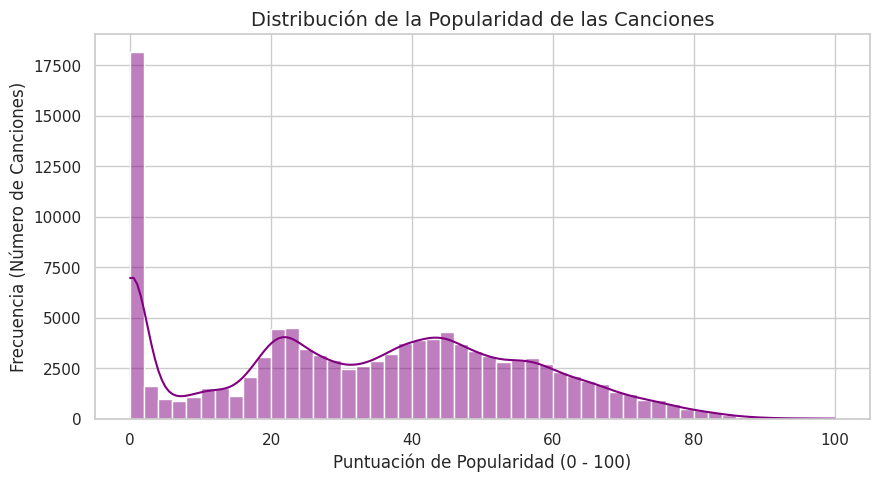

In [77]:
display(df.describe(include='all'))


plt.figure(figsize=(10, 5))
sns.histplot(df['popularity'], bins=50, kde=True, color='purple')
plt.title('Distribución de la Popularidad de las Canciones', fontsize=14)
plt.xlabel('Puntuación de Popularidad (0 - 100)')
plt.ylabel('Frecuencia (Número de Canciones)')
plt.show()

### Interpretación de la Distribución de Popularidad
*   **Comportamiento Anómalo en el Cero:** El hallazgo más crítico es el enorme pico de canciones con popularidad exactamente igual a 0. Esto sugiere que una gran parte del catálogo son canciones no escuchadas, ruido, o pistas que la plataforma acaba de subir y aún no tienen métricas.
*   **Distribución No Normal:** Descartando los ceros, la distribución tiene múltiples picos (bimodal/multimodal) concentrándose entre los valores 20 y 50. Muy pocas canciones logran superar el umbral de 80.
*   **Implicación para el Modelo:** Predecir exactamente el número de popularidad será difícil mediante regresión lineal simple debido a esta distribución.

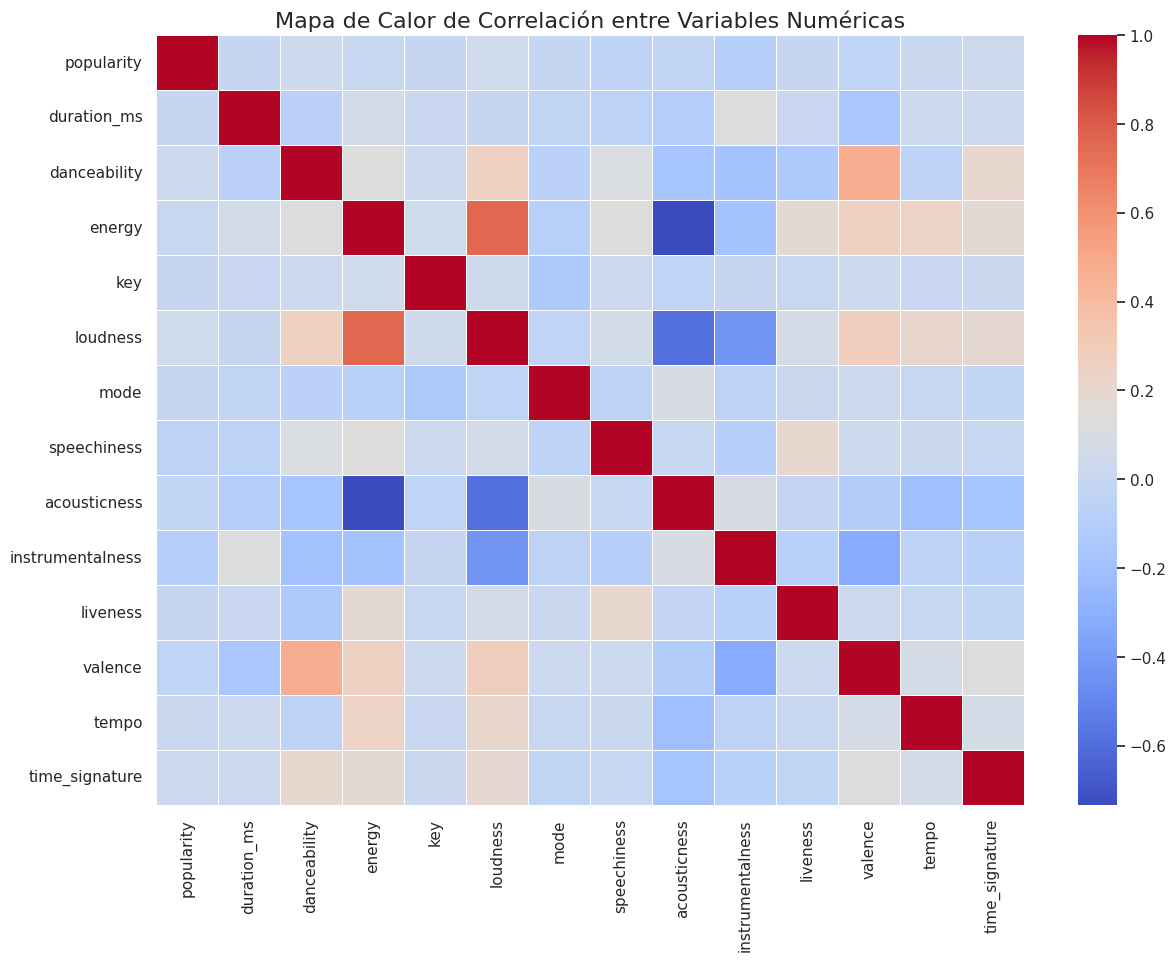

In [21]:
columnas_numericas = df.select_dtypes(include=['float64', 'int64']).columns
if 'Unnamed: 0' in columnas_numericas:
    columnas_numericas = columnas_numericas.drop('Unnamed: 0')

correlacion = df[columnas_numericas].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlacion, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Mapa de Calor de Correlación entre Variables Numéricas', fontsize=16)
plt.show()

### Interpretación del Mapa de Calor (Correlación)
*   **Correlaciones Fuertes Lógicas:** Existe una alta correlación positiva entre `energy` (energía) y `loudness` (volumen). A su vez, ambas tienen una fuerte correlación negativa con `acousticness` (acústica). Esto tiene sentido musical: las canciones acústicas no suelen ser ruidosas ni de alta energía.
*   **Relación con la Popularidad:** Sorprendentemente, ninguna de las variables numéricas acústicas presenta una correlación lineal fuerte con nuestra variable objetivo (`popularity`).
*   **Implicación para el Modelo:** Dado que no hay relaciones lineales fuertes y directas con la popularidad, los modelos simples (como Regresión Lineal) probablemente tendrán un mal rendimiento. Necesitaremos modelos más complejos que detecten patrones no lineales.

### Análisis Bivariado: Exploración de Patrones No Lineales
Para visualizar la relación directa de nuestras variables acústicas contra la variable objetivo (`popularity`), utilizamos gráficos de dispersión.

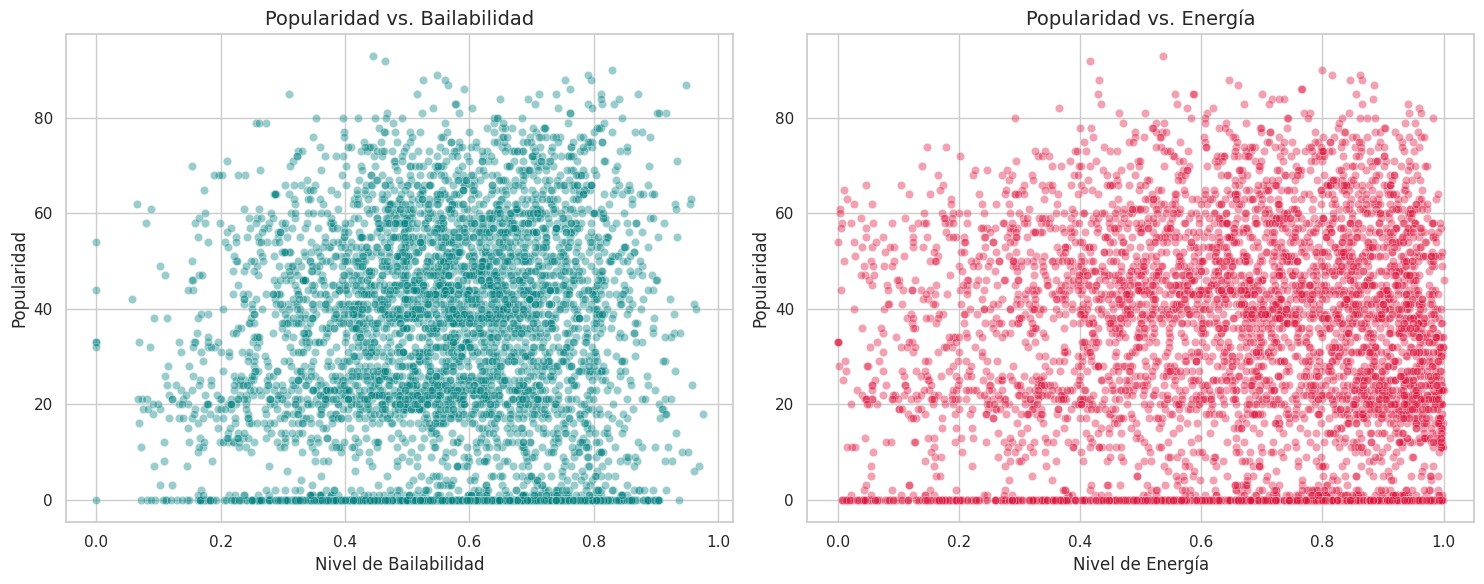

In [58]:
muestra_df = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(ax=axes[0], data=muestra_df, x='danceability', y='popularity', alpha=0.4, color='teal')
axes[0].set_title('Popularidad vs. Bailabilidad', fontsize=14)
axes[0].set_xlabel('Nivel de Bailabilidad')
axes[0].set_ylabel('Popularidad')

sns.scatterplot(ax=axes[1], data=muestra_df, x='energy', y='popularity', alpha=0.4, color='crimson')
axes[1].set_title('Popularidad vs. Energía', fontsize=14)
axes[1].set_xlabel('Nivel de Energía')
axes[1].set_ylabel('Popularidad')

plt.tight_layout()
plt.show()

**Interpretación de los Gráficos de Dispersión:**
*   **Falta de Linealidad:** Las nubes de puntos confirman el hallazgo del mapa de calor; no existe una línea recta que indique "a mayor bailabilidad, mayor popularidad". Los datos están muy dispersos.
*   **El Muro de los Ceros:** Se observa una fuerte línea horizontal de puntos en el nivel de popularidad 0, abarcando todos los rangos posibles de energía y bailabilidad. Esto refuerza la teoría de que la popularidad nula no se debe a la acústica de la canción, sino a su falta de exposición, antigüedad o métricas faltantes en la plataforma.
*   **Decisión Técnica:** Queda descartado el uso de algoritmos básicos como la Regresión Lineal Simple. Necesitaremos modelos basados en árboles (Decision Trees, Random Forest) o redes neuronales que puedan capturar interacciones complejas.

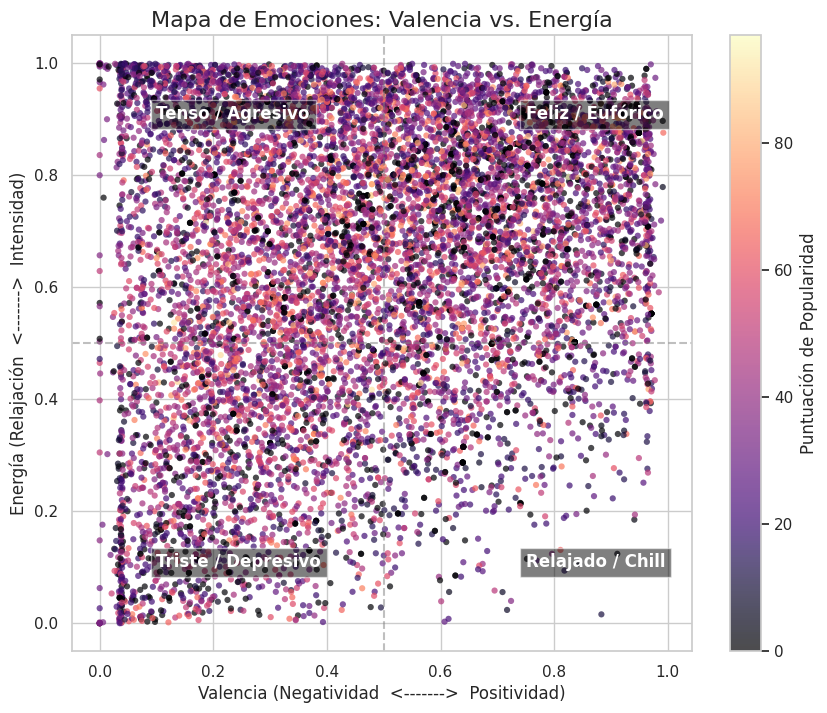

In [78]:
muestra_emociones = df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(x=muestra_emociones['valence'],
                      y=muestra_emociones['energy'],
                      c=muestra_emociones['popularity'],
                      cmap='magma', alpha=0.7, edgecolors='none', s=20)

plt.colorbar(scatter, label='Puntuación de Popularidad')

plt.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)

plt.title('Mapa de Emociones: Valencia vs. Energía', fontsize=16)
plt.xlabel('Valencia (Negatividad  <------->  Positividad)', fontsize=12)
plt.ylabel('Energía (Relajación  <------->  Intensidad)', fontsize=12)

plt.text(0.1, 0.9, 'Tenso / Agresivo', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.75, 0.9, 'Feliz / Eufórico', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.1, 0.1, 'Triste / Depresivo', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))
plt.text(0.75, 0.1, 'Relajado / Chill', fontsize=12, color='white', weight='bold', bbox=dict(facecolor='black', alpha=0.5))

plt.show()

**Implicaciones del Mapa de Emociones para el Modelo Predictivo**

*   **Interacción de Características (Feature Interaction):** El gráfico demuestra que el algoritmo no podrá predecir el éxito evaluando estas variables de forma aislada. Una canción tensa (baja valencia) puede ser un éxito masivo, pero *solo si* viene acompañada de alta energía. Necesitaremos entrenar modelos capaces de entender combinaciones complejas y espacios multidimensionales.
*   **Descarte de Modelos Lineales:** La dispersión de la nube de puntos confirma la ausencia de una correlación lineal simple. Un algoritmo de Regresión Lineal básica tendrá un rendimiento deficiente porque intentará trazar una línea recta donde claramente existen agrupaciones o "cuadrantes" de comportamiento.

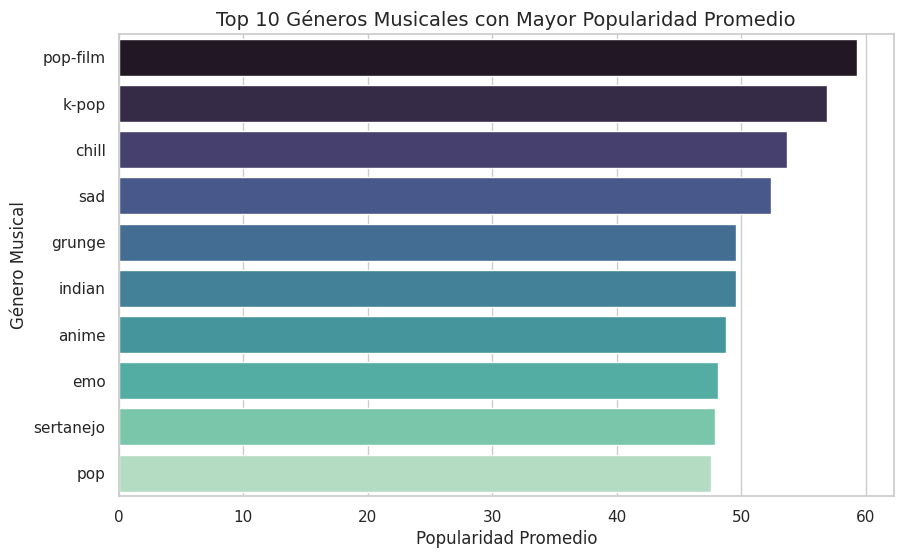

In [22]:
top_generos = df.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_generos.values, y=top_generos.index, hue=top_generos.index, legend=False, palette='mako')
plt.title('Top 10 Géneros Musicales con Mayor Popularidad Promedio', fontsize=14)
plt.xlabel('Popularidad Promedio')
plt.ylabel('Género Musical')
plt.show()

### Interpretación de Variables Categóricas (Top Géneros)
*   **Impacto del Género:** A diferencia de las variables numéricas, el género musical (`track_genre`) sí parece tener un impacto drástico en la popularidad.
*   Géneros de nicho cinematográfico (`pop-film`) o fenómenos globales (`k-pop`) lideran la plataforma con promedios cercanos a 60, mientras que la media general del dataset es de solo 33.2.
*   **Implicación para la Fase 3:** Será fundamental transformar correctamente esta columna de texto a formato numérico (One-Hot Encoding o Target Encoding) para que el modelo de Machine Learning pueda aprovechar esta valiosa información.

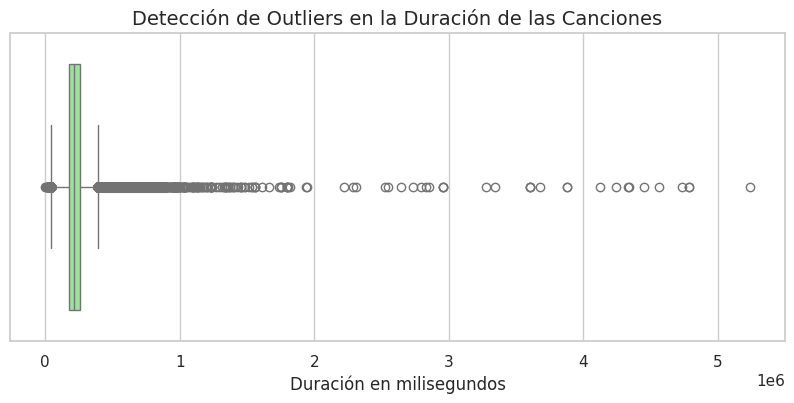

In [23]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['duration_ms'], color='lightgreen')
plt.title('Detección de Outliers en la Duración de las Canciones', fontsize=14)
plt.xlabel('Duración en milisegundos')
plt.show()

### Interpretación de Outliers (Duración)
*   **Valores Extremos:** El diagrama de caja revela una cantidad masiva de valores atípicos (outliers) en el extremo superior.
*   Mientras que el promedio (mean) es de aproximadamente 228,000 milisegundos (unos 3.8 minutos), existen pistas que superan los 5 millones de milisegundos (más de 80 minutos). Esto podría corresponder a ruidos blancos, podcasts mal clasificados o sesiones de meditación.
*   **Implicación para la Fase 3:** Estos valores extremos pueden sesgar y confundir al algoritmo predictivo. En la etapa de Preparación de Datos, deberemos decidir si eliminar las canciones que superen cierto umbral de duración (por ejemplo, más de 10 minutos) para que el modelo se enfoque en música comercial estándar.

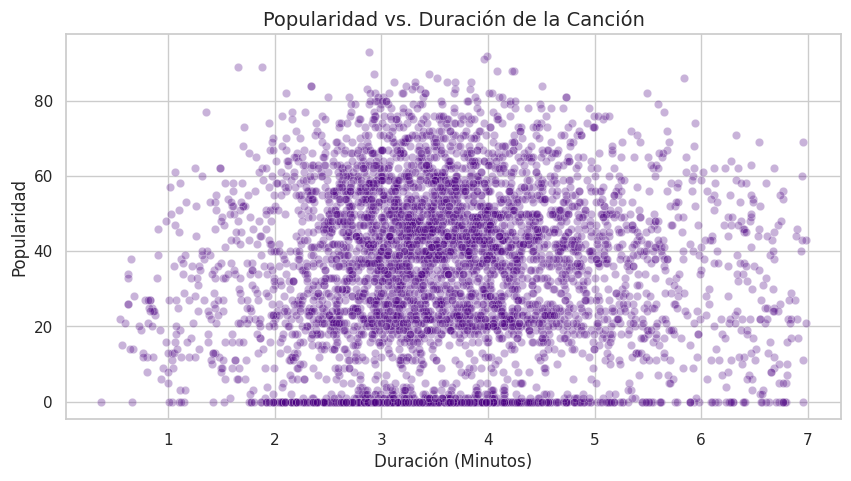

In [76]:
df_duracion = df[df['duration_ms'] < 420000].copy()
df_duracion['duration_min'] = df_duracion['duration_ms'] / 60000

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_duracion.sample(5000, random_state=42), x='duration_min', y='popularity', alpha=0.3, color='indigo')
plt.title('Popularidad vs. Duración de la Canción', fontsize=14)
plt.xlabel('Duración (Minutos)')
plt.ylabel('Popularidad')
plt.show()

**Interpretación de la Duración (Implicaciones para el Modelo)**

*   A partir de los 5 minutos, la probabilidad de alcanzar una alta popularidad cae de forma drástica.
*   **Decisión técnica:** Para la fase de ingeniería de características, será estratégico convertir la variable continua `duration_ms` en categorías discretas (ej. "Corta", "Radio Edit", "Larga"). Esto le dará al algoritmo un atajo matemático directo para premiar las canciones que caen en la ventana de mayor éxito comercial.

### Análisis de Cardinalidad (Variables Categóricas)
Es crucial entender cuántos valores únicos existen en nuestras variables de texto para determinar cómo las transformaremos matemáticamente más adelante y detectar posibles anomalías en los registros.

In [39]:
columnas_texto = df.select_dtypes(include=['object'])

print("--- VALORES ÚNICOS POR COLUMNA (CARDINALIDAD) ---")
for col in columnas_texto.columns:
    unicos = df[col].nunique()
    print(f"{col}: {unicos} valores únicos")

total_filas = len(df)
tracks_unicos = df['track_id'].nunique()

print("\n--- ANÁLISIS DE DUPLICADOS ---")
print(f"Total de registros: {total_filas}")
print(f"IDs de canciones únicas: {tracks_unicos}")
if tracks_unicos < total_filas:
    print(f"Existen {total_filas - tracks_unicos} registros duplicados en el dataset.")

--- VALORES ÚNICOS POR COLUMNA (CARDINALIDAD) ---
track_id: 89741 valores únicos
artists: 31437 valores únicos
album_name: 46589 valores únicos
track_name: 73608 valores únicos
track_genre: 114 valores únicos

--- ANÁLISIS DE DUPLICADOS ---
Total de registros: 114000
IDs de canciones únicas: 89741
Existen 24259 registros duplicados en el dataset.


**Interpretación de la Cardinalidad y Hallazgo Crítico:**

*   **Diversidad de Géneros:** El catálogo cuenta con exactamente 114 géneros musicales (`track_genre`). Esta es una cantidad ideal para que el algoritmo pueda segmentar el mercado de manera granular.
*   **Alerta de Duplicados (Data Leakage):** El análisis revela un problema severo en la estructura del dataset original. De las 114,000 filas totales, solo 89,741 corresponden a canciones únicas (`track_id`). Esto significa que tenemos **24,259 registros duplicados**.
*   **Razón probable:** Es altamente probable que una misma canción haya sido clasificada por Spotify en más de un género a la vez, generando una fila nueva por cada género asignado.
*   **Implicación para la Fase 3:** Esto es crítico. Si entrenamos un modelo de Machine Learning con datos duplicados, sufriremos de *Data Leakage* (fuga de datos), haciendo que el modelo parezca artificialmente bueno porque memorizó canciones repetidas. En la siguiente fase habrá que decidir como manejamos estos datos.

In [43]:
conteo_generos = df['track_genre'].value_counts()
pd.set_option('display.max_rows', 150)
print(conteo_generos)

pd.reset_option('display.max_rows')

track_genre
acoustic             1000
afrobeat             1000
alt-rock             1000
alternative          1000
ambient              1000
anime                1000
black-metal          1000
bluegrass            1000
blues                1000
brazil               1000
breakbeat            1000
british              1000
cantopop             1000
chicago-house        1000
children             1000
chill                1000
classical            1000
club                 1000
comedy               1000
country              1000
dance                1000
dancehall            1000
death-metal          1000
deep-house           1000
detroit-techno       1000
disco                1000
disney               1000
drum-and-bass        1000
dub                  1000
dubstep              1000
edm                  1000
electro              1000
electronic           1000
emo                  1000
folk                 1000
forro                1000
french               1000
funk                 1000


In [45]:
generos_por_cancion = df.groupby(['track_id', 'track_name'])['track_genre'].agg(list).reset_index()

generos_por_cancion['cantidad_generos'] = generos_por_cancion['track_genre'].apply(len)

canciones_multi_genero = generos_por_cancion[generos_por_cancion['cantidad_generos'] > 1].sort_values(by='cantidad_generos', ascending=False)

print(f"Total de canciones únicas con múltiples géneros: {len(canciones_multi_genero)}")
print("\nTop 10 canciones repetidas y sus géneros asignados:")
display(canciones_multi_genero.head(10))

Total de canciones únicas con múltiples géneros: 16641

Top 10 canciones repetidas y sus géneros asignados:


,track_id,track_name,track_genre,cantidad_generos
74275,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,"[blues, country, folk, j-pop, j-rock, power-po...",9
25739,2Ey6v4Sekh3Z0RUSISRosD,Layla,"[blues, british, country, folk, hard-rock, psy...",8
31723,2kkvB3RNRzwjFdGhaUA0tz,Layla,"[blues, british, country, folk, hard-rock, psy...",8
64109,5ZsAhuQ24mWHiduaxJqnhW,Udd Gaye,"[edm, hip-hop, indian, indie-pop, indie, pop-f...",7
65253,5ftfVzSLIi5ZxYdNbRtf41,Never Gonna Give You Up,"[alt-rock, alternative, blues, garage, punk-ro...",7
5012,0RSGPiykniIg8m7JhiAVv7,Aisi Raaton,"[indian, indie-pop, indie, k-pop, pop-film, si...",7
69227,61202Zzk9rk4bPMZLh2gr6,Trouble No More,"[blues, country, folk, hard-rock, j-rock, sing...",7
88605,7tbzfR8ZvZzJEzy6v0d6el,Liggi,"[edm, hip-hop, indian, indie-pop, indie, pop-f...",7
33705,2vU6bm5hVF2idVknGzqyPL,Christmas (Baby Please Come Home),"[alt-rock, alternative, metal, punk-rock, punk...",7
7396,0e5LcankE0UyJUuCoq1uH2,The Joker,"[blues, country, folk, hard-rock, psych-rock, ...",7


### Evidencia Empírica de Duplicidad Multigénero

*   **Volumen Afectado:** Existen 16,641 canciones que aparecen más de una vez en el catálogo debido a clasificaciones simultáneas.
*   **Casos Extremos:** El caso más evidente es la pista "Baby Blue - Remastered 2010", la cual fue insertada 9 veces en el *dataset* bajo géneros musicalmente incompatibles entre sí (como *blues*, *j-pop* y *country*). "Never Gonna Give You Up" también sufre este fenómeno apareciendo en 7 categorías distintas.
*   **Impacto Predictivo:** Si el modelo de Machine Learning ve "Baby Blue" 9 veces durante su entrenamiento con exactamente las mismas características acústicas, memorizará la canción en lugar de aprender patrones generales (*Overfitting* o Sobreajuste).
*   **Resolución:** En la etapa de Preparación de Datos, eliminaremos las filas duplicadas basándonos en el `track_id`, conservando únicamente la primera aparición de cada canción y descartando las redundancias.

In [48]:
indice_max_popularidad = df['popularity'].idxmax()
hit_absoluto = df.loc[indice_max_popularidad]

print("--- EL MAYOR ÉXITO INDIVIDUAL ---")
print(f"Artista: {hit_absoluto['artists']}")
print(f"Álbum: {hit_absoluto['album_name']}")
print(f"Canción: {hit_absoluto['track_name']}")
print(f"Puntuación: {hit_absoluto['popularity']}/100\n")

artistas_frecuentes = df['artists'].value_counts()
artistas_validos = artistas_frecuentes[artistas_frecuentes >= 5].index

top_artistas = df[df['artists'].isin(artistas_validos)].groupby('artists')['popularity'].mean()
top_artistas = top_artistas.sort_values(ascending=False).head(5)

print("--- TOP 5 ARTISTAS (PROMEDIO MÁS ALTO) ---")
print(top_artistas)
print("\n")

albumes_frecuentes = df['album_name'].value_counts()
albumes_validos = albumes_frecuentes[albumes_frecuentes >= 3].index

top_albumes = df[df['album_name'].isin(albumes_validos)].groupby('album_name')['popularity'].mean()
top_albumes = top_albumes.sort_values(ascending=False).head(5)

print("--- TOP 5 ÁLBUMES (PROMEDIO MÁS ALTO) ---")
print(top_albumes)

--- EL MAYOR ÉXITO INDIVIDUAL ---
Artista: Sam Smith;Kim Petras
Álbum: Unholy (feat. Kim Petras)
Canción: Unholy (feat. Kim Petras)
Puntuación: 100/100

--- TOP 5 ARTISTAS (PROMEDIO MÁS ALTO) ---
artists
Olivia Rodrigo             87.400000
Bad Bunny                  87.083333
Bad Bunny;Jhayco           87.000000
The Chainsmokers;Halsey    84.000000
Marshmello;Khalid          84.000000
Name: popularity, dtype: float64


--- TOP 5 ÁLBUMES (PROMEDIO MÁS ALTO) ---
album_name
La Bachata                                                             98.000000
I Ain’t Worried (Music From The Motion Picture "Top Gun: Maverick")    96.000000
I'm Good (Blue)                                                        91.000000
L3tra                                                                  90.500000
Un Verano Sin Ti                                                       90.142857
Name: popularity, dtype: float64


**Interpretación de los Líderes de Popularidad:**

*   **Éxito Absoluto:** La canción "Unholy" de Sam Smith y Kim Petras es el registro que alcanzó el tope métrico de la plataforma (100/100) en esta extracción.
*   **Dominio del Mercado (Artistas):** Al promediar los catálogos (con al menos 5 pistas), la plataforma está dominada por el Pop contemporáneo y el Reggaetón, con **Olivia Rodrigo** (87.4) y **Bad Bunny** (87.08) a la cabeza.
*   **Anomalía en Metadatos (Colaboraciones):** El sistema registra las colaboraciones fusionando los nombres (ej. `Bad Bunny;Jhayco` o `The Chainsmokers;Halsey`). En un entorno de negocio real, esta estructura diluye las estadísticas individuales de un artista y obliga a separar los nombres (Data Cleaning) para medir el impacto real de cada cantante.
*   **Consistencia de Álbumes:** Discos de música latina ("La Bachata", "Un Verano Sin Ti") y bandas sonoras ("Top Gun: Maverick") mantienen un promedio de éxito masivo por encima de los 90 puntos, demostrando que no solo tienen un "hit", sino que el álbum entero es consumido por los usuarios.

### Análisis de Contenido Explícito
Nos interesa descubrir si las canciones con letras explícitas (`explicit` = True) tienen un rendimiento diferente en términos de popularidad en comparación con las canciones aptas para todo público. Utilizaremos un diagrama de caja (boxplot) para comparar sus distribuciones.

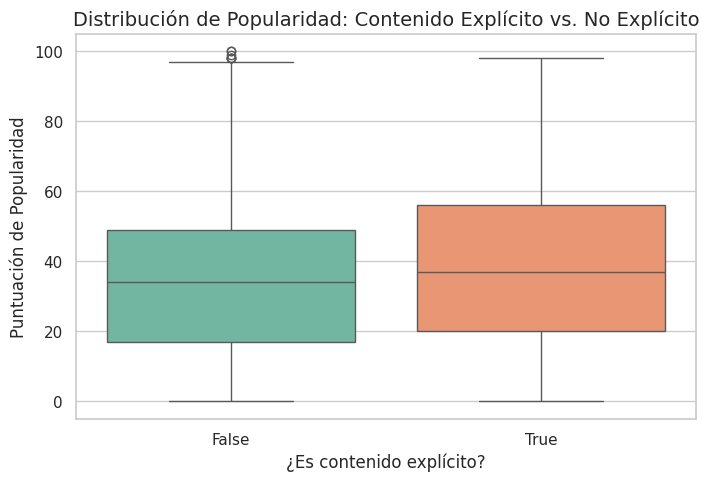

Promedio de popularidad:
No Explícito (False): 32.94
Explícito (True): 36.45


In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='explicit', y='popularity', hue='explicit', palette='Set2', legend=False)
plt.title('Distribución de Popularidad: Contenido Explícito vs. No Explícito', fontsize=14)
plt.xlabel('¿Es contenido explícito?')
plt.ylabel('Puntuación de Popularidad')
plt.show()

promedios_explicito = df.groupby('explicit')['popularity'].mean()
print("Promedio de popularidad:")
print(f"No Explícito (False): {promedios_explicito[False]:.2f}")
print(f"Explícito (True): {promedios_explicito[True]:.2f}")

**Interpretación del Impacto Explícito:**
*   Aunque el promedio general del dataset es bajo, las canciones con contenido explícito tienden a tener una popularidad promedio ligeramente superior y una mediana más alta que las canciones no explícitas.
*   Esto puede deberse a que los géneros que actualmente dominan las listas de éxitos mundiales (como el hip-hop, rap o reggaetón) suelen contener lenguaje explícito de forma natural.
*   **Implicación para el Modelo:** La variable `explicit` ya está en formato booleano, pero en la Fase 3 la convertiremos a formato numérico (0 y 1) para que el algoritmo pueda ponderarla correctamente.

### Conclusión General de la Fase 2

Tras un Análisis Exploratorio de Datos (EDA) hemos perfilado el comportamiento del catálogo y detectado anomalías que definirán la estrategia de nuestro modelo.

**Resumen de Hallazgos:**
*   **Falta de Linealidad:** Las variables acústicas puras (como energía o bailabilidad) no presentan una correlación lineal directa con la popularidad, lo que descarta modelos simples como la regresión lineal y orienta el proyecto hacia algoritmos complejos capaces de capturar patrones no lineales.
*   **Interacción Multidimensional (Mapa de Emociones):** Variables como positividad (`valence`) e intensidad (`energy`) operan de forma conjunta; el éxito comercial se concentra en cuadrantes específicos y en los márgenes se detectaron concentraciones anómalas de pistas con popularidad cero (audios corruptos o sin métricas).
*   **Impacto Categórico y de Metadatos:** Los metadatos comerciales y géneros musicales (`track_genre`, `explicit`) muestran diferencias estadísticas claras en la popularidad promedio, a diferencia de variables planas como la tonalidad (`key`) o el modo (`mode`).
*   **Sesgo (Data Leakage):** La validación estadística confirmó un balance forzado de exactamente 1,000 canciones por cada uno de los 114 géneros, generando 24,259 registros duplicados (con pistas repetidas hasta 9 veces) que provocarían *overfitting* si no se corrigen.
*   **Anomalías de Rango:** La inspección de dispersión y percentiles reveló valores extremos e irreales en la duración de las pistas, con un máximo superior a 87 minutos (`duration_ms`).


